# MuJoCo: Unitree G1 tossing an apple hand-to-hand
Runtime: any (GPU gives EGL rendering; on CPU set `MUJOCO_GL` to `osmesa` and `apt install libosmesa6-dev`).

**Run the cells top to bottom. After editing `toss_sim.py`, use Runtime -> Restart session and run all again.**

In [ ]:
!pip -q install mujoco mediapy matplotlib

In [ ]:
%%writefile toss_sim.py
"""
toss_sim.py - Unitree G1 humanoid tossing an apple from the left hand to the right hand (MuJoCo).

Needs: pip install mujoco mediapy numpy matplotlib      (mujoco >= 3.2 for MjSpec)
Model: Unitree G1 (29 DoF) from google-deepmind/mujoco_menagerie (cloned automatically).

How it works
------------
* MjSpec edits the stock G1 scene at load time:
    - adds a free-flying 'apple' (sphere, 0.15 kg, r = 4 cm, friction 1.2)
    - adds a shallow "cup" (disc + rim) on each wrist_yaw_link as a palm.
      The cup only collides with the apple (contype/conaffinity bit 4), never with the robot.
* Balance: the pelvis is pinned to its standing pose (pin_base=True). Legs are PD-held.
* Control: damped-least-squares IK drives each palm site (position + "palm faces up" orientation)
  with a nullspace pull to the home posture. Joint PD + velocity feedforward + gravity compensation.
* Left hand : scripted toss (constant-acceleration stroke, quick decel), then a RETREAT (down and
              outward, clear of the apple) and a minimum-jerk RETURN to the starting palm position.
* Right hand: closed loop - predicts where the apple will cross the catch plane, moves there,
              and on contact "gives" downward (exponential cushion) to absorb the impact.
"""
import os
os.environ.setdefault("MUJOCO_GL", "egl")
import subprocess
import numpy as np
import mujoco

# ----------------------------------------------------------------------------- constants
G = 9.81
APPLE_R, APPLE_M = 0.04, 0.15
PALM_POS = np.array([0.08, 0.0, 0.0])
PAD_R, PAD_HALF = 0.065, 0.006
PALM_ROLL_DEG = {"left": -90.0, "right": 90.0}
PALM_NORMAL = {s: (0.0, float(np.sin(np.radians(r))), float(np.cos(np.radians(r))))
               for s, r in PALM_ROLL_DEG.items()}
OFF_Z = PAD_HALF + APPLE_R + 0.001
ARM = ["shoulder_pitch", "shoulder_roll", "shoulder_yaw", "elbow",
       "wrist_roll", "wrist_pitch", "wrist_yaw"]
ORI_W = 0.5
CUSHION_TAU = 0.05
MENAGERIE = "mujoco_menagerie"

DIRECT_TORQUE = True
QD_FILT = 0.3
LEAD = 0.02
RETREAT_DROP = 0.10      #how far the palm drops right after release
RETREAT_SIDE = 0.06      #outward move (+y = away from the body for the left hand)
RETREAT_TIME = 0.15      #duration of the retreat
RETURN_TIME = 0.5        #duration of the move back to the start
T_DEC = 0.05             #deceleration time after release


def gains(joint_name):
    """(kp, kd, torque_limit)."""
    if "wrist" in joint_name:
        return 60.0, 2.0, 20.0
    if "shoulder" in joint_name or "elbow" in joint_name:
        return 400.0, 12.0, 60.0
    if "waist" in joint_name:
        return 400.0, 15.0, 80.0
    return 300.0, 10.0, 80.0


def fetch_model():
    if not os.path.isdir(MENAGERIE):
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/google-deepmind/mujoco_menagerie.git"], check=True)
    return os.path.join(MENAGERIE, "unitree_g1", "scene.xml")


def build_model(scene_xml):
    spec = mujoco.MjSpec.from_file(scene_xml)
    spec.option.timestep = 0.002
    spec.option.integrator = mujoco.mjtIntegrator.mjINT_IMPLICITFAST
    spec.visual.global_.offwidth = 1920
    spec.visual.global_.offheight = 1080

    for side in ("left", "right"):
        w = spec.body(f"{side}_wrist_yaw_link")
        n = np.asarray(PALM_NORMAL[side], float)
        q = np.zeros(4)
        mujoco.mju_quatZ2Vec(q, n / np.linalg.norm(n))
        Rm = np.zeros(9)
        mujoco.mju_quat2Mat(Rm, q)
        Rm = Rm.reshape(3, 3)
        w.add_site(name=f"{side}_palm", pos=PALM_POS, quat=q, size=[0.01, 0.01, 0.01], rgba=[0, 1, 0, 1])
        w.add_geom(name=f"{side}_pad", type=mujoco.mjtGeom.mjGEOM_CYLINDER, quat=q,
                   size=[PAD_R, PAD_HALF, 0], pos=PALM_POS, mass=0.03,
                   contype=4, conaffinity=4, condim=4, friction=[1.2, 0.02, 0.005],
                   rgba=[0.2, 0.5, 0.9, 1])
        nseg = 10
        for k in range(nseg):
            a = 2 * np.pi * k / nseg
            qt = np.zeros(4)
            mujoco.mju_mulQuat(qt, q, np.array([np.cos(a / 2), 0, 0, np.sin(a / 2)]))
            w.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.006, 0.022, 0.010], mass=0.004,
                       pos=PALM_POS + Rm @ np.array([PAD_R * np.cos(a), PAD_R * np.sin(a), 0.010]),
                       quat=qt,
                       contype=4, conaffinity=4, condim=4, friction=[1.2, 0.02, 0.005],
                       rgba=[0.2, 0.5, 0.9, 1])

    apple = spec.worldbody.add_body(name="apple", pos=[0, 0, 3.0])
    apple.add_freejoint()
    apple.add_geom(name="apple_geom", type=mujoco.mjtGeom.mjGEOM_SPHERE, size=[APPLE_R, 0, 0],
                   mass=APPLE_M, contype=5, conaffinity=5, condim=4,
                   friction=[1.2, 0.02, 0.005], rgba=[0.85, 0.1, 0.1, 1])

    for key in spec.keys:
        q = np.asarray(key.qpos)
        if q.size:
            key.qpos = np.concatenate([q, [0, 0, 3.0, 1, 0, 0, 0]])
    return spec.compile()


def rate_limit(cur, tgt, vmax, dt):
    return cur + np.clip(tgt - cur, -vmax * dt, vmax * dt)


def min_jerk(x):
    """Minimum-jerk blend 0 -> 1 with zero velocity and acceleration at both ends."""
    x = np.clip(x, 0.0, 1.0)
    return 10 * x ** 3 - 15 * x ** 4 + 6 * x ** 5


class TossSim:
    sides = ("left", "right")

    def __init__(self, pin_base=True, scene=None):
        self.pin_base = pin_base
        m = self.m = build_model(scene or fetch_model())
        self.d, self.k = mujoco.MjData(m), mujoco.MjData(m)
        assert m.jnt_type[0] == mujoco.mjtJoint.mjJNT_FREE, "expected the first joint to be the pelvis freejoint"

        key = mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_KEY, "stand")
        self.key_id = max(key, 0)
        apple_jnt = m.body_jntadr[m.body("apple").id]
        self.apple_q = int(m.jnt_qposadr[apple_jnt])
        self.apple_v = int(m.jnt_dofadr[apple_jnt])

        self.sh = {s: m.body(f"{s}_shoulder_pitch_link").id for s in self.sides}
        self.site = {s: m.site(f"{s}_palm").id for s in self.sides}
        jids = {s: [m.joint(f"{s}_{j}_joint").id for j in ARM] for s in self.sides}
        self.qadr = {s: np.array([m.jnt_qposadr[j] for j in jids[s]]) for s in self.sides}
        self.dadr = {s: np.array([m.jnt_dofadr[j] for j in jids[s]]) for s in self.sides}
        self.lo = {s: m.jnt_range[jids[s], 0].copy() for s in self.sides}
        self.hi = {s: m.jnt_range[jids[s], 1].copy() for s in self.sides}

        for j in range(m.njnt):
            if m.jnt_type[j] == mujoco.mjtJoint.mjJNT_HINGE:
                da = m.jnt_dofadr[j]
                m.dof_damping[da] = gains(m.joint(j).name)[1]
                m.dof_armature[da] = max(m.dof_armature[da], 0.01)

        self.act = []
        for a in range(m.nu):
            j = int(m.actuator_trnid[a, 0])
            is_pos = int(m.actuator_biastype[a]) == int(mujoco.mjtBias.mjBIAS_AFFINE)
            self.act.append((a, int(m.jnt_qposadr[j]), gains(m.joint(j).name)[0], is_pos,
                             float(m.actuator_gainprm[a, 0]) or 1.0,
                             bool(m.actuator_ctrllimited[a]), m.actuator_ctrlrange[a].copy()))
        self.dof_pd = []
        for a in range(m.nu):
            j = int(m.actuator_trnid[a, 0])
            kp, kd, lim = gains(m.joint(j).name)
            self.dof_pd.append((int(m.jnt_dofadr[j]), int(m.jnt_qposadr[j]), kp, lim, kd))
        self.qd_target = np.zeros(m.nv)
        if DIRECT_TORQUE:
            m.opt.disableflags |= int(mujoco.mjtDisableBit.mjDSBL_ACTUATION)
        self._snap = None
        self.reset(fresh=True)
    def ik_step(self, side, p_des, q, max_step=0.1, gain=0.8):
        m, k = self.m, self.k
        k.qpos[:] = self.d.qpos
        k.qpos[self.qadr[side]] = q
        mujoco.mj_kinematics(m, k)
        mujoco.mj_comPos(m, k)
        sid = self.site[side]
        jp, jr = np.zeros((3, m.nv)), np.zeros((3, m.nv))
        mujoco.mj_jacSite(m, k, jp, jr, sid)
        cols = self.dadr[side]
        J = np.vstack([jp[:, cols], ORI_W * jr[:, cols]])
        z_axis = k.site_xmat[sid].reshape(3, 3)[:, 2]
        err = np.concatenate([p_des - k.site_xpos[sid], ORI_W * np.cross(z_axis, [0, 0, 1.0])])
        Jp = J.T @ np.linalg.inv(J @ J.T + 1e-4 * np.eye(6))
        dq = gain * (Jp @ err)
        dq += (np.eye(len(q)) - Jp @ J) @ (0.05 * (self.q_home[self.qadr[side]] - q))
        n = np.linalg.norm(dq)
        if n > max_step:
            dq *= max_step / n
        return np.clip(q + dq, self.lo[side], self.hi[side])

    def apply_control(self):
        d = self.d
        if DIRECT_TORQUE:
            for dof, qa, kp, lim, kd in self.dof_pd:
                tau = kp * (self.q_target[qa] - d.qpos[qa]) + kd * self.qd_target[dof] + d.qfrc_bias[dof]
                d.qfrc_applied[dof] = np.clip(tau, -lim, lim)
            return
        for a, qa, kp, is_pos, gain, lim, rng in self.act:
            qt = self.q_target[qa]
            u = qt if is_pos else kp * (qt - d.qpos[qa]) / gain
            d.ctrl[a] = np.clip(u, rng[0], rng[1]) if lim else u

    def step(self, p_left, p_right):
        """One physics step with palm-position commands (world frame)."""
        d = self.d
        dt = self.m.opt.timestep
        for s, p in (("left", p_left), ("right", p_right)):
            ad = self.qadr[s]
            q_new = self.ik_step(s, p, self.q_target[ad])
            qd = (q_new - self.q_target[ad]) / dt
            da = self.dadr[s]
            self.qd_target[da] += QD_FILT * (qd - self.qd_target[da])
            self.q_target[ad] = q_new
        self.apply_control()
        if self.pin_base:
            d.qpos[:7] = self.q_home[:7]
            d.qvel[:6] = 0
        mujoco.mj_step(self.m, d)
    def _build_ready(self, settle):
        m, d = self.m, self.d
        mujoco.mj_resetDataKeyframe(m, d, self.key_id)
        mujoco.mj_forward(m, d)
        self.q_home = d.qpos.copy()
        self.q_target = d.qpos.copy()
        c = 0.5 * (d.xpos[self.sh["left"]] + d.xpos[self.sh["right"]])
        want = {"left": c + [0.25, 0.13, -0.22], "right": c + [0.25, -0.13, -0.22]}
        for s in self.sides:
            q = self.q_target[self.qadr[s]].copy()
            for _ in range(800):
                q = self.ik_step(s, want[s], q, max_step=0.05)
            self.q_target[self.qadr[s]] = q
            d.qpos[self.qadr[s]] = q
        mujoco.mj_forward(m, d)
        self.ready = {s: d.site_xpos[self.site[s]].copy() for s in self.sides}
        self.cmd = {s: self.ready[s].copy() for s in self.sides}
        for s in self.sides:
            print(f"{s} palm ready-pose error: {np.linalg.norm(self.ready[s] - want[s])*100:.1f} cm")
        d.qpos[self.apple_q:self.apple_q + 7] = np.r_[self.ready["left"] + [0, 0, OFF_Z], 1, 0, 0, 0]
        d.qvel[:] = 0
        t_end = d.time + settle
        while d.time < t_end:
            self.step(self.cmd["left"], self.cmd["right"])
        self._snap = (d.qpos.copy(), d.qvel.copy(), d.time, self.q_target.copy(),
                      {s: v.copy() for s, v in self.cmd.items()})

    def reset(self, vz=1.5, stroke=0.12, settle=0.8, fresh=False):
        if self._snap is None or fresh:
            self._build_ready(settle)
        qpos, qvel, t, qt, cmd = self._snap
        d = self.d
        d.qpos[:], d.qvel[:], d.time, d.ctrl[:] = qpos, qvel, t, 0
        self.q_target = qt.copy()
        self.qd_target[:] = 0
        self.cmd = {s: v.copy() for s, v in cmd.items()}
        mujoco.mj_forward(self.m, d)
        self.plan_toss(vz, stroke)
        self.t_start = d.time
        self.t_rel = self.t_start + self.t_acc
        self.catch = None

    def plan_toss(self, vz, stroke):
        """Constant-acceleration stroke of length `stroke` ending with palm velocity v, chosen so the
        ballistic apple lands at the right palm's catch point."""
        d = self.d
        A = d.site_xpos[self.site["left"]].copy()
        target = self.ready["right"] + [0, 0, OFF_Z]
        u = np.array([0, 0, 1.0])
        for _ in range(10):
            B = A + u * stroke
            rel = B + [0, 0, OFF_Z]
            T = (vz + np.sqrt(vz ** 2 + 2 * G * (rel[2] - target[2]))) / G
            v = np.r_[(target[:2] - rel[:2]) / T, vz]
            u = v / np.linalg.norm(v)
        self.A, self.v_rel, self.t_acc = A, v, 2 * stroke / np.linalg.norm(v)
        self.acc, self.t_dec = v / self.t_acc, T_DEC
        self.B = A + u * stroke
        self.flight_time = T

    def left_traj(self, t):
        ts = t + LEAD - self.t_start
        if ts < 0:
            return self.A
        if ts < self.t_acc:
            return self.A + 0.5 * self.acc * ts ** 2
        tau = ts - self.t_acc
        if tau < self.t_dec:
            return self.B + self.v_rel * tau - 0.5 * (self.v_rel / self.t_dec) * tau ** 2
        C = self.B + 0.5 * self.v_rel * self.t_dec
        D = C + np.array([0.0, RETREAT_SIDE, -RETREAT_DROP])
        t2 = tau - self.t_dec
        if t2 < RETREAT_TIME:
            return C + min_jerk(t2 / RETREAT_TIME) * (D - C)
        tr = (t2 - RETREAT_TIME) / RETURN_TIME
        if tr >= 1:
            return self.A
        return D + min_jerk(tr) * (self.A - D)

    def ball_state(self):
        d = self.d
        return d.qpos[self.apple_q:self.apple_q + 3].copy(), d.qvel[self.apple_v:self.apple_v + 3].copy()

    def right_target(self, t):
        ball, v = self.ball_state()
        base = self.ready["right"]
        palm = self.d.site_xpos[self.site["right"]]
        if self.catch is not None:
            tau = t - self.catch["t"]
            tgt = self.catch["p"].copy()
            tgt[2] += min(self.catch["vz"], 0.0) * CUSHION_TAU * (1 - np.exp(-tau / CUSHION_TAU))
            return tgt
        if t < self.t_rel:
            return base
        rel = ball - palm
        if v[2] < 0 and rel[2] < OFF_Z + 0.015 and np.abs(rel[:2]).max() < 0.06:
            self.catch = {"t": t, "p": self.cmd["right"].copy(), "vz": v[2]}
            return self.cmd["right"]
        zc = base[2] + OFF_Z
        disc = v[2] ** 2 + 2 * G * (ball[2] - zc)
        tc = (v[2] + np.sqrt(disc)) / G if disc > 0 else -1
        if tc > 0:
            xy = np.clip(ball[:2] + v[:2] * tc, base[:2] - 0.14, base[:2] + 0.14)
            return np.array([xy[0], xy[1], base[2]])
        return self.cmd["right"]

    def preview_hands(self, size=(360, 480)):
        """Close-up stills of both hands at the ready pose, to check which way the cup faces."""
        self.reset(fresh=True)
        r = mujoco.Renderer(self.m, height=size[0], width=size[1])
        imgs = []
        for s in self.sides:
            cam = mujoco.MjvCamera()
            cam.lookat[:] = self.d.site_xpos[self.site[s]]
            cam.distance, cam.azimuth, cam.elevation = 0.6, 150, -25
            r.update_scene(self.d, cam)
            imgs.append(r.render())
        return imgs

    def run(self, t_total=3.0, render=True, fps=60, size=(480, 640), cam_cfg=None, **reset_kw):
        """cam_cfg: optional dict(lookat=[x,y,z], distance=, azimuth=, elevation=) for the camera."""
        self.reset(**reset_kw)
        m, d = self.m, self.d
        dt = m.opt.timestep
        log = {k: [] for k in ("t", "ball", "left", "right")}
        frames = []
        if render:
            renderer = mujoco.Renderer(m, height=size[0], width=size[1])
            cam = mujoco.MjvCamera()
            cfg = dict(lookat=[0.25, 0.0, 0.95], distance=2.0, azimuth=150, elevation=-10)
            cfg.update(cam_cfg or {})
            cam.lookat[:] = cfg["lookat"]
            cam.distance, cam.azimuth, cam.elevation = cfg["distance"], cfg["azimuth"], cfg["elevation"]
            next_frame = d.time
        t_stop = self.t_start + t_total
        while d.time < t_stop:
            t = d.time
            self.cmd["right"] = rate_limit(self.cmd["right"], self.right_target(t), 3.0, dt)
            self.step(self.left_traj(t), self.cmd["right"])
            log["t"].append(d.time - self.t_start)
            log["ball"].append(d.qpos[self.apple_q:self.apple_q + 3].copy())
            log["left"].append(d.site_xpos[self.site["left"]].copy())
            log["right"].append(d.site_xpos[self.site["right"]].copy())
            if render and d.time >= next_frame:
                renderer.update_scene(d, cam)
                frames.append(renderer.render())
                next_frame += 1.0 / fps
        log = {k: np.array(v) for k, v in log.items()}
        ball, _ = self.ball_state()
        rel = ball - d.site_xpos[self.site["right"]]
        log["caught"] = bool(abs(rel[2] - OFF_Z) < 0.02 and np.linalg.norm(rel[:2]) < 0.05 and ball[2] > 0.5)
        log["frames"] = frames
        return log


def plot_log(log):
    import matplotlib.pyplot as plt
    t, b = log["t"], log["ball"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(t, b[:, 2], label="apple z"); ax[0].plot(t, log["left"][:, 2], "--", label="left palm z")
    ax[0].plot(t, log["right"][:, 2], "--", label="right palm z"); ax[0].set_xlabel("t [s]"); ax[0].legend()
    ax[1].plot(t, b[:, 1], label="apple y"); ax[1].plot(t, log["left"][:, 1], "--", label="left palm y")
    ax[1].plot(t, log["right"][:, 1], "--", label="right palm y"); ax[1].set_xlabel("t [s]"); ax[1].legend()
    plt.tight_layout(); plt.show()


def make_video(sim, log, path="apple_toss.mp4", fps_out=20, render_fps=60,
               title="Unitree G1: hand-to-hand apple toss (3x slow motion)"):
    """Side-by-side MP4: simulation on the left, live graphs with a moving cursor on the right."""
    import matplotlib.pyplot as plt
    import mediapy as media
    frames = log["frames"]
    H, W = frames[0].shape[:2]
    t, b, L, R = log["t"], log["ball"], log["left"], log["right"]
    t_rel = sim.t_rel - sim.t_start
    t_catch = (sim.catch["t"] - sim.t_start) if sim.catch else None

    fig, axs = plt.subplots(2, 1, figsize=(W * 0.8 / 100, H / 100), dpi=100)
    for ax, i, name in ((axs[0], 2, "height z [m]"), (axs[1], 1, "lateral y [m]")):
        ax.plot(t, b[:, i], label="apple")
        ax.plot(t, L[:, i], "--", label="left palm")
        ax.plot(t, R[:, i], "--", label="right palm")
        ax.axvline(t_rel, color="gray", lw=0.8)
        ax.text(t_rel, ax.get_ylim()[1], " release", va="top", fontsize=8)
        if t_catch is not None:
            ax.axvline(t_catch, color="gray", lw=0.8)
            ax.text(t_catch, ax.get_ylim()[1], " catch", va="top", fontsize=8)
        ax.set_ylabel(name); ax.grid(alpha=0.3)
    axs[0].legend(loc="center right", fontsize=8); axs[1].set_xlabel("t [s]")
    fig.suptitle(title, fontsize=10)
    cursors = [ax.axvline(0, color="red", lw=1.5) for ax in axs]
    fig.tight_layout()

    out = []
    for k, fr in enumerate(frames):
        for c in cursors:
            c.set_xdata([k / render_fps, k / render_fps])
        fig.canvas.draw()
        plot = np.asarray(fig.canvas.buffer_rgba())[..., :3]
        out.append(np.hstack([fr, plot[:H]]))
    out = [out[0]] * fps_out + out + [out[-1]] * fps_out
    media.write_video(path, out, fps=fps_out)
    plt.close(fig)
    return path


def hand_clearance(log, t_after=0.2):
    """Smallest apple-above-left-palm gap after release (resting = OFF_Z). Near OFF_Z => palm touched apple."""
    gap = log["ball"][:, 2] - log["left"][:, 2]
    return float(gap[log["t"] > t_after].min())


def success_sweep(sim, vzs=(1.2, 1.5, 1.8), n=20, seed=0):
    """Catch success rate vs launch speed with randomised stroke length."""
    rng = np.random.default_rng(seed)
    rates = []
    for vz in vzs:
        wins = 0
        for _ in range(n):
            r = sim.run(t_total=2.0, render=False, vz=vz, stroke=rng.uniform(0.10, 0.13))
            wins += int(r["caught"])
        rates.append(wins / n)
        print(f"vz={vz:.2f} m/s: {wins}/{n} caught")
    return list(vzs), rates


Writing toss_sim.py


In [ ]:
%%writefile toss_env.py
"""
toss_env.py - Gymnasium wrapper around TossSim for PPO (stable-baselines3).

Left hand : scripted toss with randomised launch speed (so the policy must generalise).
Right hand: the RL policy outputs a 3-D palm velocity command (IK + joint PD do the rest).
Base      : pinned (pin_base=True) - balance is NOT part of this task.

Reward (dense): -distance(apple, ideal rest point on right palm) after release, +bonus while the apple
sits still on the cup, -10 if it falls, small action penalty.
"""
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from toss_sim import TossSim, OFF_Z


class AppleCatchEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, ctrl_dt=0.02, max_time=1.5, vmax=2.5, seed=None):
        super().__init__()
        self.sim = TossSim(pin_base=True)
        self.n_sub = int(round(ctrl_dt / self.sim.m.opt.timestep))
        self.dt, self.max_time, self.vmax = ctrl_dt, max_time, vmax
        self.rng = np.random.default_rng(seed)
        self.action_space = spaces.Box(-1.0, 1.0, (3,), np.float32)
        self.observation_space = spaces.Box(-np.inf, np.inf, (12,), np.float32)

    def _obs(self):
        s = self.sim
        ball, v = s.ball_state()
        palm = s.d.site_xpos[s.site["right"]]
        t = s.d.time - s.t_start
        released = float(s.d.time > s.t_rel)
        return np.concatenate([ball - palm, v, s.cmd["right"] - s.ready["right"],
                               [released, np.clip(t, 0, 3), 0.0]]).astype(np.float32)

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        s = self.sim
        s.reset(vz=self.rng.uniform(1.3, 1.7), stroke=self.rng.uniform(0.10, 0.13))
        s.catch = None
        return self._obs(), {}

    def step(self, action):
        s, a = self.sim, np.clip(action, -1, 1)
        base = s.ready["right"]
        for _ in range(self.n_sub):
            tgt = np.clip(s.cmd["right"] + a * self.vmax * s.m.opt.timestep, base - 0.14, base + 0.14)
            s.cmd["right"] = tgt
            s.step(s.left_traj(s.d.time), s.cmd["right"])
        ball, v = s.ball_state()
        palm = s.d.site_xpos[s.site["right"]]
        rel = ball - palm - np.array([0, 0, OFF_Z])
        t = s.d.time - s.t_start
        released = s.d.time > s.t_rel
        reward = -0.01 * float(np.sum(a ** 2))
        if released:
            reward += -np.linalg.norm(rel)
            if np.linalg.norm(rel) < 0.03 and np.linalg.norm(v) < 0.5:
                reward += 2.0
        fell = ball[2] < palm[2] - 0.20
        if fell:
            reward -= 10.0
        truncated = t > self.max_time
        return self._obs(), float(reward), bool(fell), bool(truncated), {}


Writing toss_env.py


## 0. Check the cup orientation on each palm

left palm ready-pose error: 0.0 cm
right palm ready-pose error: 0.0 cm
left palm ready-pose error: 0.0 cm
right palm ready-pose error: 0.0 cm


left hand,right hand

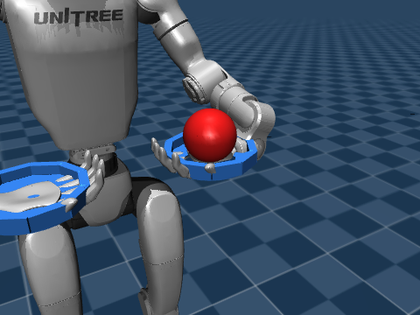
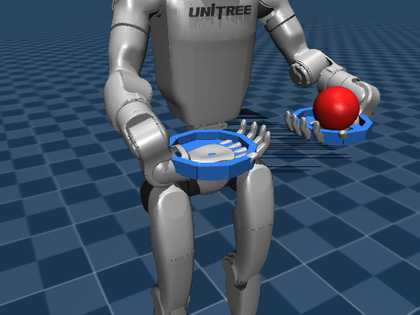

In [ ]:
import os; os.environ['MUJOCO_GL']='egl'
import mediapy as media
from toss_sim import TossSim
sim = TossSim(pin_base=True)
media.show_images(sim.preview_hands(), width=420, titles=['left hand','right hand'])

## 1. Run the toss (left hand tosses, retreats, returns; right hand catches)

caught: True | final apple height: 0.82
min apple-above-palm gap after release: -0.062 m (resting = 0.047)


This browser does not support the video tag.


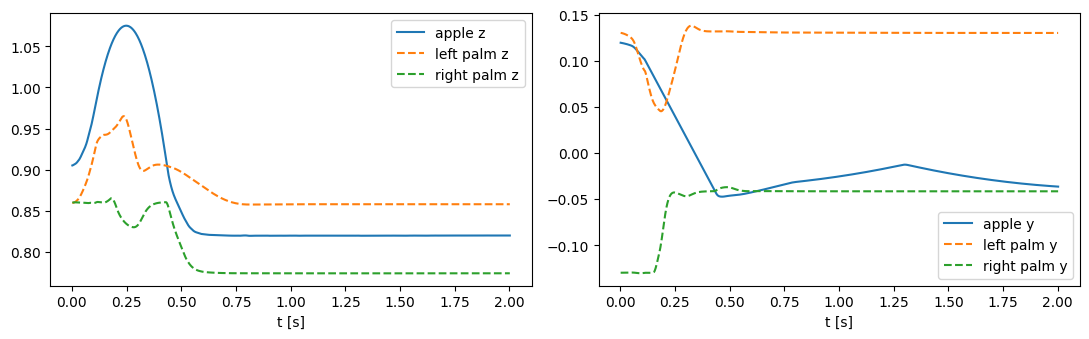

In [ ]:
import numpy as np, mediapy as media
from toss_sim import plot_log, hand_clearance, OFF_Z

log = sim.run(t_total=2.0, vz=1.5, stroke=0.12, fps=60)
print('caught:', log['caught'], '| final apple height:', round(float(log['ball'][-1,2]),3))
print('min apple-above-palm gap after release: %.3f m (resting = %.3f)' % (hand_clearance(log), OFF_Z))

media.show_video(log['frames'], fps=20)
plot_log(log)

### Tuning knobs (top of `toss_sim.py`)
- `RETREAT_DROP`, `RETREAT_SIDE`: raise if the palm still touches the apple; lower if the arm cannot reach
- `RETREAT_TIME`, `RETURN_TIME`, `T_DEC`: speed of the return motion
- `LEAD`, `QD_FILT`, `gains()`: arm tracking speed (launch speeds `vz` up to ~1.8 m/s work, beyond ~1.9 the arm runs out of torque)
- `CUSHION_TAU`, pad friction, `PAD_R`: catch quality

## 2. Success rate vs launch speed (results figure)

vz=1.20 m/s: 20/20 caught
vz=1.40 m/s: 20/20 caught
vz=1.60 m/s: 20/20 caught
vz=1.80 m/s: 17/20 caught
vz=2.00 m/s: 9/20 caught


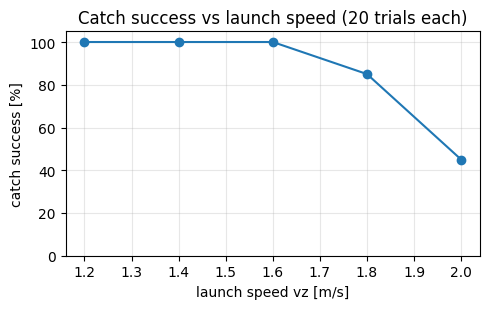

In [ ]:
import matplotlib.pyplot as plt
from toss_sim import success_sweep
vzs, rates = success_sweep(sim, vzs=(1.2, 1.4, 1.6, 1.8, 2.0), n=20)
plt.figure(figsize=(5,3.2)); plt.plot(vzs, [100*r for r in rates], 'o-')
plt.xlabel('launch speed vz [m/s]'); plt.ylabel('catch success [%]'); plt.ylim(0,105); plt.grid(alpha=.3)
plt.title('Catch success vs launch speed (20 trials each)'); plt.tight_layout(); plt.savefig('success_rate.png', dpi=200); plt.show()

## 3. Export videos


In [ ]:
from toss_sim import make_video
from google.colab import files

log_hd = sim.run(t_total=2.0, vz=1.5, stroke=0.12, fps=60, size=(720, 1280))
p = make_video(sim, log_hd, path='apple_toss.mp4')
files.download(p)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

close = dict(lookat=[float(x) for x in sim.ready['right'] + [0, 0, 0.1]], distance=0.8, azimuth=150, elevation=-15)
log_cu = sim.run(t_total=2.0, vz=1.5, stroke=0.12, fps=60, size=(720, 1280), cam_cfg=close)
media.write_video('apple_toss_closeup.mp4', log_cu['frames'], fps=20)
files.download('apple_toss_closeup.mp4')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>